# TD SESSION3 BASE VECTORIELLE - ML- DITI4

In [1]:
# Installation des dépendances
!pip install pillow chromadb open_clip_torch tqdm ipykernel

zsh:1: command not found: pip


9 images trouvées


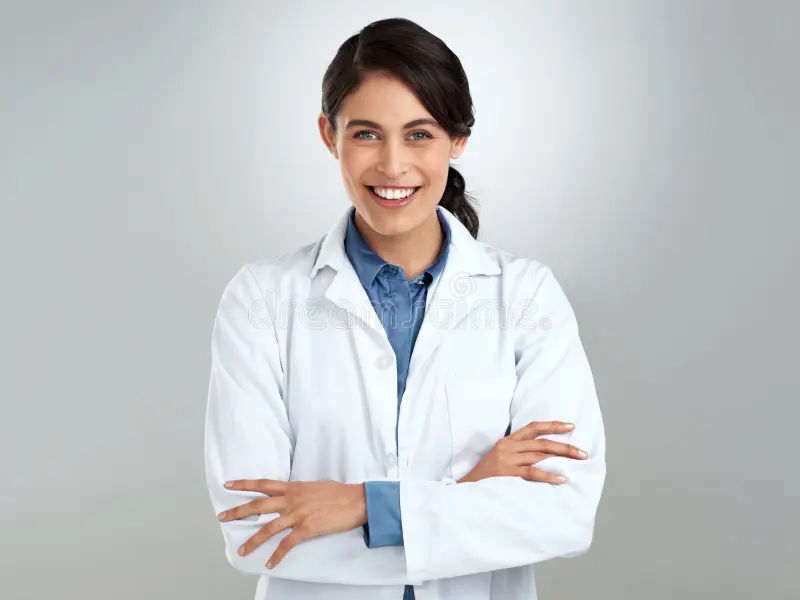

In [29]:
from PIL import Image
import glob

fichiers = sorted(
    f for ext in ("jpeg", "jpg", "png")
    for f in glob.glob(f"images/personnes/*.{ext}")
)
print(len(fichiers), "images trouvées")

listeImages = [Image.open(f) for f in fichiers]
if listeImages:
    display(listeImages[0])
else:
    print("Aucune image dans images/personnes/ : ajoutez des photos.")


In [30]:
import chromadb
from chromadb.utils.data_loaders import ImageLoader
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction

BV_chromabd = chromadb.PersistentClient(path="db_storePersonnes")

chargeImages = ImageLoader()
VectorisationImages = OpenCLIPEmbeddingFunction()

chromadb = BV_chromabd.get_or_create_collection(
    name="personnes",
    data_loader=chargeImages,
    embedding_function=VectorisationImages
)


In [31]:
import os

indexImage = []
CheminImages = []
dossierImages = "images/personnes"

for index, image_name in enumerate(sorted(os.listdir(dossierImages))):
    if image_name.lower().endswith((".jpeg", ".jpg", ".png")):
        image_path = os.path.join(dossierImages, image_name)
        indexImage.append(str(index))
        CheminImages.append(image_path)

print(indexImage[:21])
print(CheminImages[:21])


['0', '1', '2', '3', '4', '5', '6', '7', '8']
['images/personnes/femme blanch 2.png', 'images/personnes/femme blanche.png', 'images/personnes/femme noire.png', 'images/personnes/femme.png', 'images/personnes/homme blanc.png', 'images/personnes/homme noir.png', 'images/personnes/homme noire 2.png', 'images/personnes/homme noire.png', 'images/personnes/image.png']


In [32]:
chromadb.add(ids=indexImage, uris=CheminImages)

In [33]:
chromadb.count()

9

In [57]:
rechercheParText = chromadb.query(
    query_texts=["affiche l'image d'une femme noire"],
    n_results=1,
    include=["uris", "distances"]
)

rechercheParText

{'ids': [['6']],
 'embeddings': None,
 'documents': None,
 'uris': [['images/personnes/homme noire 2.png']],
 'included': ['uris', 'distances'],
 'data': None,
 'metadatas': None,
 'distances': [[0.8205375075340271]]}

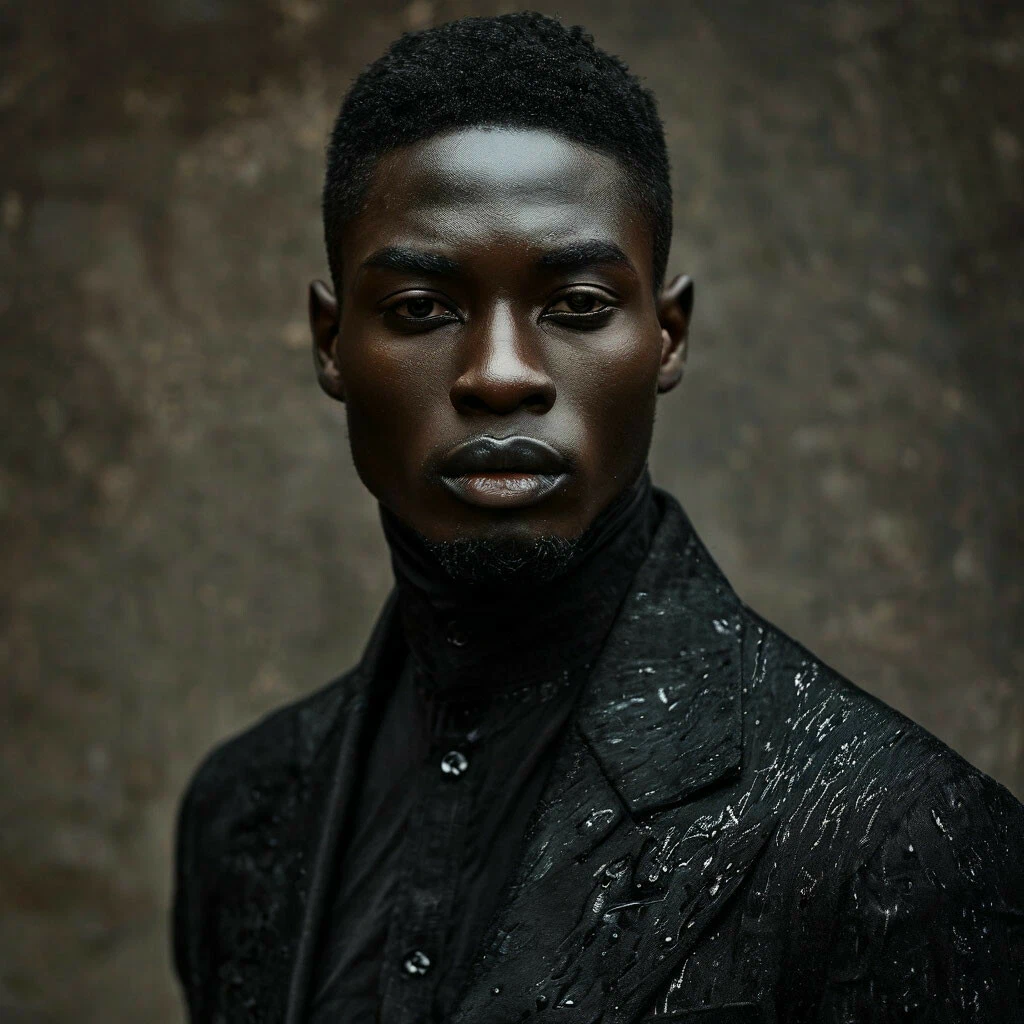

In [59]:
for image in rechercheParText["uris"][0]:
    display(Image.open(image))